In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay



In [3]:
# Step 1: Load dataset
data = pd.read_csv("iris (2).csv")

print(data.head())
print("Missing Values:")
print(data.isnull().sum())


   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [4]:

# Step 2: Separate features and target
X = data[["sepal_length", "sepal_width", "petal_length", "petal_width"]]
y = data["species"]

# Step 3: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



In [5]:
# Step 4: Train Gaussian Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)

nb_predictions = nb.predict(X_test)

# Step 5: Train Decision Tree
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

tree_predictions = tree.predict(X_test)


In [6]:

# Step 6: Evaluate Gaussian Naive Bayes
print("\nGaussian Naive Bayes Results")

print("Accuracy:", accuracy_score(y_test, nb_predictions))
print("Precision:", precision_score(y_test, nb_predictions, average="macro"))
print("Recall:", recall_score(y_test, nb_predictions, average="macro"))
print("F1 Score:", f1_score(y_test, nb_predictions, average="macro"))

# Step 7: Evaluate Decision Tree
print("\nDecision Tree Results")

print("Accuracy:", accuracy_score(y_test, tree_predictions))
print("Precision:", precision_score(y_test, tree_predictions, average="macro"))
print("Recall:", recall_score(y_test, tree_predictions, average="macro"))
print("F1 Score:", f1_score(y_test, tree_predictions, average="macro"))



Gaussian Naive Bayes Results
Accuracy: 0.9666666666666667
Precision: 0.9696969696969697
Recall: 0.9666666666666667
F1 Score: 0.9665831244778612

Decision Tree Results
Accuracy: 0.9666666666666667
Precision: 0.9696969696969697
Recall: 0.9666666666666667
F1 Score: 0.9665831244778612


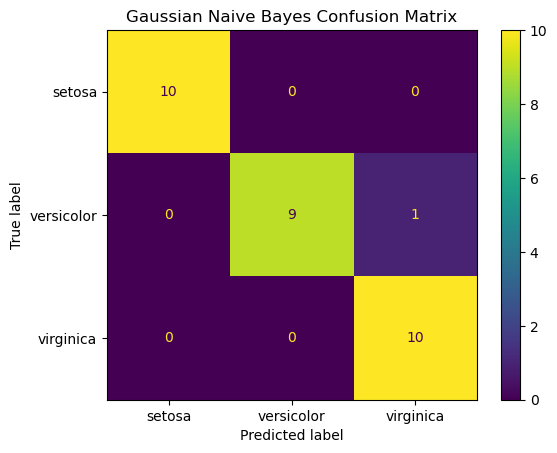

In [7]:

# Step 8: Gaussian Naive Bayes Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, nb_predictions)
plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.show()


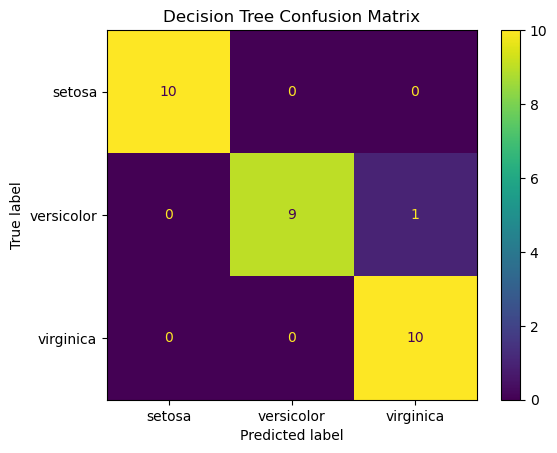

In [8]:

# Step 9: Decision Tree Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, tree_predictions)
plt.title("Decision Tree Confusion Matrix")
plt.show()


In [9]:

# Step 10: Predict a new flower
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

print("\nGaussian NB Prediction:", nb.predict(new_flower)[0])
print("Decision Tree Prediction:", tree.predict(new_flower)[0])



Gaussian NB Prediction: setosa
Decision Tree Prediction: setosa
